<a href="https://colab.research.google.com/github/DennOrtiz/MPM_200_DennOrtiz/blob/main/dennise_ortiz_assignment_1_will__hummers_survive.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/EpiPandit/MPM_200/blob/main/Session%205/Assignment%201%20-%20Will%20the%20Hummers%20Survive.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🐦 MPM 200 · Week 1 Assignment: *Will the Hummers Survive?*

**Due:** Wednesday 28 October 2026, 9:00 AM · **Total:** 50 points + 5 bonus

**Ground rules**
* Show your work: code **and** output. It lets us follow your thinking and give partial credit.
* Work together, but don't copy. Read each other's code until you could have written it yourself.
* Cells with blanks (`____`) won't run until you fill them in. That's on purpose.

## 📟 Mission briefing

You're the wildlife veterinarian on call for three California wildlife rehabilitation centers. Every year, hummingbirds arrive in shoeboxes and teacups: stunned by windows, carried in by cats, fallen from nests. Some go on to fly again; many don't.

The centers have pooled **more than 25 years of intake records (1991–2016)**. Your mission is to find out **which birds make it back to the sky, and what tips the odds.**

### 🗂️ Case file: data dictionary

| Column | What it records |
|---|---|
| `Admitted` | Date the bird arrived at the center |
| `Disposition_binary` | Outcome: **Died** or **Released** |
| `Place` | Rehabilitation center |
| `F_Aid` | Did the finder give first aid? (Yes/No) |
| `Species_e` | `ANHU` = Anna's Hummingbird · `BCHU` = Black-chinned Hummingbird · `Selasphorus` = orange *Selasphorus* species (e.g., Allen's, Rufous) not identified to species · `Non-selasphorus` = green birds not identified to species |
| `Sex_e`, `Age_e` | Sex and age class as recorded |
| `Brought_in_after` | Days the finder kept the bird before bringing it in |
| `season` | Season of admission |
| `r` | Reason for admission |
| `Green_Orange` | Broad group: green (non-*Selasphorus*) or orange (*Selasphorus*) |
| `ID` | Unique ID for each bird |

## 🍄 Case file 0 · Warm-up: make some noise (2 pts)

**Q0.** Install **beepr** and play the **Mario** sound. Then have a cowsay animal welcome you to the mission (use your name!).

> **Why the helper below?** `beep()` plays sound on the computer *running R*. On Colab that's a Google server with no speakers, so you'd hear nothing. The helper sends the very same sound file to **your browser** instead. On your own laptop, plain `beep("mario")` works.

In [ ]:
install.packages(c("beepr", "cowsay"))
library(beepr)
library(cowsay)

# Plays a beepr sound in your browser (for Colab)
beep_colab <- function(sound = "smb_stage_clear") {     # smb_stage_clear = the Mario sound
  wav <- list.files(system.file("sounds", package = "beepr"),
                    pattern = sound, full.names = TRUE)[1]
  b64 <- jsonlite::base64_enc(readBin(wav, "raw", file.info(wav)$size))
  IRdisplay::display_html(sprintf('<audio controls autoplay src="data:audio/wav;base64,%s"></audio>', b64))
}

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [ ]:
beep_colab()     # press ▶ if your browser blocks autoplay

say("Welcome to Hummingbird HQ, Dr. Ortiz!", by = "cow")


 _______________________________________ 
< Welcome to Hummingbird HQ, Dr. Ortiz! >
 --------------------------------------- 
      \
       \

        ^__^ 
        (oo)\ ________ 
        (__)\         )\ /\ 
             ||------w|
             ||      ||

In [ ]:
library(dplyr)
library(ggplot2)
options(repr.plot.width = 7, repr.plot.height = 4.5)
dir.create("outputs", showWarnings = FALSE)

## 📋 Case file 1 · Intake: read the records

**Q1 (2 pts).** Read `Hummingbird_data.csv` into an object called `data`. It lives on the course GitHub, so you can read it straight from the URL.

In [ ]:
url <- "https://raw.githubusercontent.com/EpiPandit/MPM_200_2026/main/data/Hummingbird_data.csv"
data <- read.csv(url)
colnames(data)

[1] "Admitted"           "Disposition_binary" "Place"             
 [4] "F_Aid"              "Species_e"          "Sex_e"             
 [7] "Age_e"              "Brought_in_after"   "season"            
[10] "r"                  "Green_Orange"       "ID"

**Q2 (1 pt).** 🔮 *Predict first:* 26 years, three centers. Guess how many birds: `____`.
Now find how many rows and columns `data` has.

In [ ]:
dim(data)# your code here

[1] 6908   12

Guess how many birds: 4000
Rows=6908 and Columns=12

**Q3 (3 pts).** Check the structure of the data.
* Use `str()` to see each column.
* Use `sapply()` with `class` to list every column's data type.
* Which columns are text (`character`) and which are numbers? Is `Admitted` stored as a date? Note anything that looks odd.

In [ ]:
str(data)

data_types <- sapply(data, class)
print(data_types)

'data.frame':	6908 obs. of  12 variables:
 $ Admitted          : chr  "1/2/1991" "1/2/1991" "1/4/1991" "1/5/1991" ...
 $ Disposition_binary: chr  "Died" "Released" "Died" "Died" ...
 $ Place             : chr  "Lindsey" "Lindsey" "Lindsey" "Lindsey" ...
 $ F_Aid             : chr  "No" "Yes" "No" "No" ...
 $ Species_e         : chr  "ANHU" "ANHU" "ANHU" "ANHU" ...
 $ Sex_e             : chr  "Female-like " "Female-like " "Female-like " "Female-like " ...
 $ Age_e             : chr  "adult-like" "adult-like" "adult-like" "adult-like" ...
 $ Brought_in_after  : int  1 0 0 4 0 0 0 0 0 0 ...
 $ season            : chr  "Winter" "Winter" "Winter" "Winter" ...
 $ r                 : chr  "found on the ground" "unknown" "suspect torpor-like state" "unknown" ...
 $ Green_Orange      : chr  "Non-selasphorus spp." "Non-selasphorus spp." "Non-selasphorus spp." "Non-selasphorus spp." ...
 $ ID                : chr  "1_ANHU" "2_ANHU" "3_ANHU" "4_ANHU" ...
          Admitted Disposition_binary      

✍️ **Your answer:**

Most of them are (characters) the only one that is saved as number or integer is "Brought_in_after". The Admitted date is saved as character.

### 🎲 Draw your own reproducible sample
Each of you will analyse a random sample of 5,000 birds. `set.seed()` makes "random" **repeatable**: the same seed always gives the same sample, so your instructor can reproduce your results exactly (remember the reproducibility checklist from lecture?).

👉 Replace `1225` with **your birthday as MMDD** (e.g., 3 July → `0703`, which R reads as 703).

In [ ]:
set.seed(1106)                              # ← your birthday, MMDD
model_data <- slice_sample(data, n = 5000)

**Use `model_data` for the rest of the assignment.**

**Q4 (1 pt).** How many rows and columns does `model_data` have?

In [ ]:
dim(model_data) # your code here
str(model_data)

[1] 5000   12

'data.frame':	5000 obs. of  12 variables:
 $ Admitted          : chr  "7/9/1991" "1/31/2015" "4/22/1994" "6/27/1997" ...
 $ Disposition_binary: chr  "Released" "Died" "Died" "Released" ...
 $ Place             : chr  "Lindsey" "Lindsey" "Lindsey" "Lindsey" ...
 $ F_Aid             : chr  "No" "No" "Yes" "No" ...
 $ Species_e         : chr  "Non-selasphorus" "ANHU" "ANHU" "Non-selasphorus" ...
 $ Sex_e             : chr  "unknown" "Female-like " "Female-like " "unknown" ...
 $ Age_e             : chr  "Nestling" "adult-like" "adult-like" "Nestling" ...
 $ Brought_in_after  : int  0 0 2 0 0 0 0 0 0 1 ...
 $ season            : chr  "Summer" "Winter" "Spring" "Summer" ...
 $ r                 : chr  "found on the ground" "found inside" "found on the ground" "unknown" ...
 $ Green_Orange      : chr  "Non-selasphorus spp." "Non-selasphorus spp." "Non-selasphorus spp." "Non-selasphorus spp." ...
 $ ID                : chr  "145_ANHU" "5160_ANHU" "626_ANHU" "1277_ANHU" ...


Rows=5000 and Columns=12

**Q5 (2 pts).** How many columns are **categorical** and how many are **continuous**? Name the continuous one(s). Is `ID` a useful variable for analysis?

✍️ **Your answer:**

11 columns are cathegorical and 1 column is continuous.
Yes, ID is useful because allow you to identify each bird.

**Q6 (2 pts).** Save your sample as `Hummingbird_data_YOURNAME.csv` in the `outputs` folder, and submit it. Use `row.names = FALSE`.

In [ ]:
write.csv(model_data, "outputs/Hummingbird_data_DenniseOrtiz.csv", row.names = FALSE)

## 🏥 Case file 2 · Which hospital is busiest?

Let's count how many birds each center admitted (column `Place`), using dplyr to build a summary table and ggplot2 to plot it.

In [ ]:
rehab <- model_data %>%
  group_by(Place) %>%
  summarise(count = n_distinct(ID))
rehab

Place,count
<chr>,<int>
Lindsey,4131
Santa Barbara,68
malibu,801


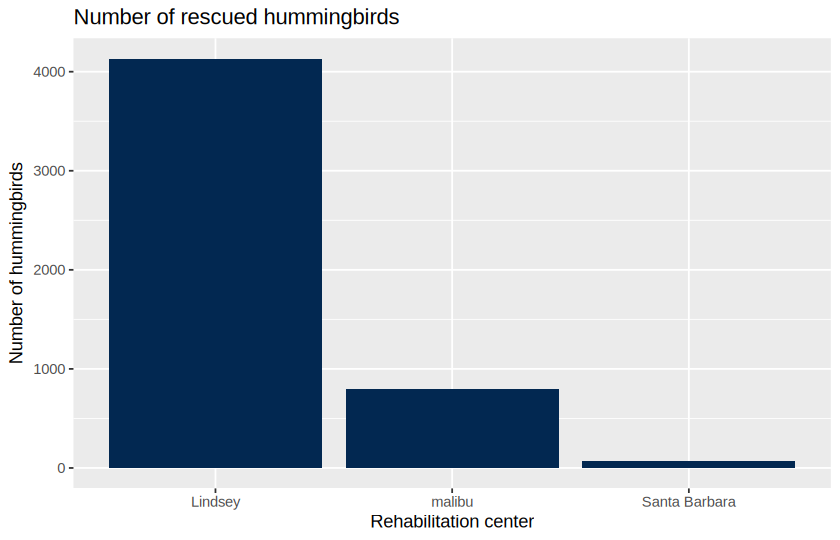

In [ ]:
p <- ggplot(rehab, aes(x = Place, y = count)) +
  geom_col(fill = "#022851") +
  xlab("Rehabilitation center") +
  ylab("Number of hummingbirds") +
  labs(title = "Number of rescued hummingbirds")
p

**Q7 (2 pts).** Save this plot as a **PDF, 4 inches wide and 3 inches tall**, and submit it.

In [ ]:
ggsave("outputs/rehab_counts_YOURNAME.pdf", p, width = 4, height = 3)

**Q8 (3 pts).** Explain the code in words, line by line, from the line that creates `rehab` through the plot. What does each function do?

1. We are creating a new data frame call Rehab from our Model data frame, we are grouping by each of place (in this case our rehabilitation center) and then, whithin each of those groups, we created a new column named counts that summarize each unique bird from our ID, lastly, we print the result of the new data frame rehab.
2. Then we are creating a new plot and we named p, with the ggplot packaged. We tell R to use the rehab data we just created and we want to put place in the X-axis and the counts in the Y-axis. With geom_col and the fill option we are choosing the color of the bars, with xlab and ylab we are chanching the labeling of the axes and with labs title we choose the title of the plot. Lastly, we print the plot p.
3. With ggsave we are able to save our plot as a file. We specify the exact location and file name where we want to save it, the plot we want to save= p, and the dimensions of the plot (wide = 4 and tall = 3).

✍️ **Your answer:**

**Q9 (2 pts).** 🤔 Lindsey admitted far more birds than the other centers. Does that mean more birds **die** at Lindsey? Why are raw counts not enough to compare outcomes between centers?

✍️ **Your answer:**

It could be that more birds die at Lindsey because it receives a larger number of birds than the other centers. However, this does not necessarily mean that Lindsey has a higher mortality rate. To properly compare the outcomes between centers, we need to calculate the mortality proportion for each center.

## 🔬 Case file 3 · Who survives?

**Q10 (6 pts).** Pick **three** variables you think could affect survival (e.g., `F_Aid`, `Age_e`, `r`, `season`, `Sex_e`, `Species_e`).
For **each** variable:
1. Make a table counting unique birds (`ID`) for every combination of the variable and `Disposition_binary`.
2. Plot it as bars, split into panels with `facet_grid()`.

Copy the two cells below for each variable.

In [ ]:
df <- model_data %>%
  group_by(season, Disposition_binary) %>%
  summarise(count = n_distinct(ID), .groups = "drop")
df

season,Disposition_binary,count
<chr>,<chr>,<int>
Fall,Died,359
Fall,Released,64
Spring,Died,1328
Spring,Released,920
Summer,Died,971
Summer,Released,623
Winter,Died,548
Winter,Released,187


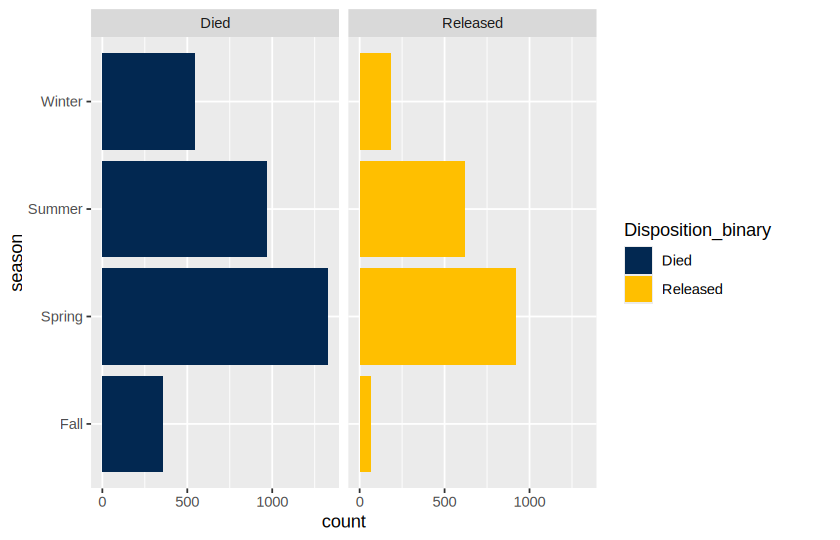

In [ ]:
ggplot(df, aes(x = season, y = count, fill = Disposition_binary)) +
  geom_col() +
  facet_grid(. ~ Disposition_binary) +
  coord_flip() +
  scale_fill_manual(values = c(Died = "#022851", Released = "#FFBF00"))

In [ ]:
df2 <- model_data %>%
  group_by(Age_e, Disposition_binary) %>%
  summarise(count = n_distinct(ID), .groups = "drop")
df2

Age_e,Disposition_binary,count
<chr>,<chr>,<int>
Nestling,Died,442
Nestling,Released,763
adult-like,Died,2764
adult-like,Released,1031


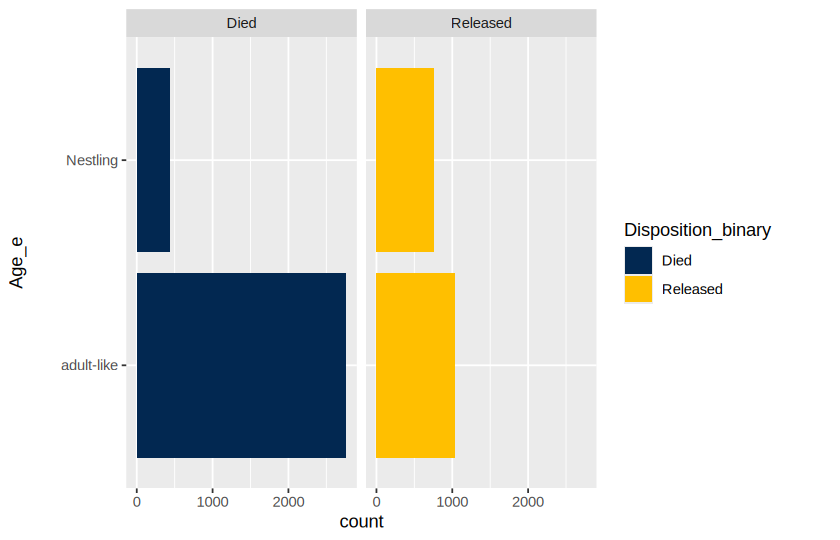

In [ ]:
ggplot(df2, aes(x = Age_e, y = count, fill = Disposition_binary)) +
  geom_col() +
  facet_grid(. ~ Disposition_binary) +
  coord_flip() +
  scale_fill_manual(values = c(Died = "#022851", Released = "#FFBF00"))

In [ ]:
df3 <- model_data %>%
  group_by(r, Disposition_binary) %>%
  summarise(count = n_distinct(ID), .groups = "drop")
df3

r,Disposition_binary,count
<chr>,<chr>,<int>
caught by domestic animal,Died,481
caught by domestic animal,Released,174
found inside,Died,113
found inside,Released,43
found on the ground,Died,1408
found on the ground,Released,740
nest-related,Died,260
nest-related,Released,407
suspect torpor-like state,Died,87


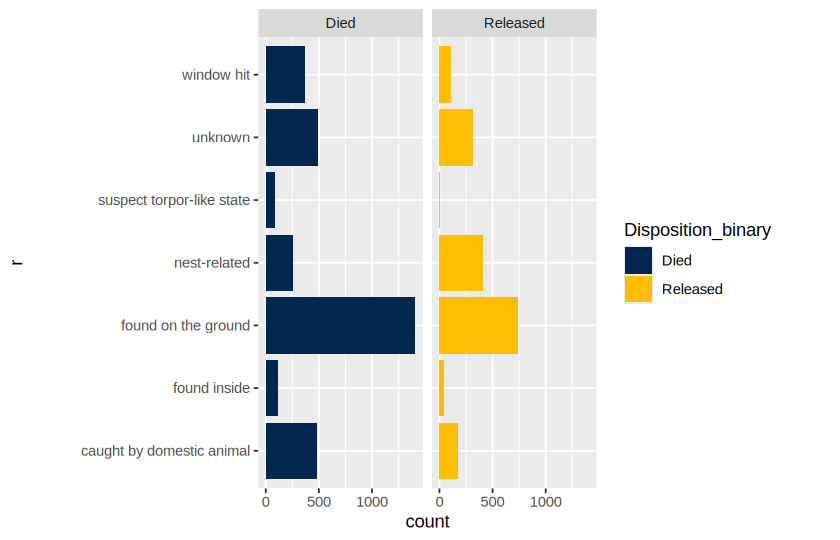

In [ ]:
ggplot(df3, aes(x = r, y = count, fill = Disposition_binary)) +
  geom_col() +
  facet_grid(. ~ Disposition_binary) +
  coord_flip() +
  scale_fill_manual(values = c(Died = "#022851", Released = "#FFBF00"))

**Q11 (4 pts).** What do your tables and plots suggest? Which variables look associated with the outcome? Which **statistical test** could check whether the association is more than chance?

✍️ **Your answer:**

### 📊 From counts to proportions
**Q12 (5 pts).** Calculate the proportion of birds **released vs. died** at each center, show the table, and plot it as side-by-side bars.

Place,Disposition_binary,count,proportion
<chr>,<chr>,<int>,<dbl>
Lindsey,Died,2661,0.6441540
Lindsey,Released,1470,0.3558460
Santa Barbara,Died,39,0.5735294
Santa Barbara,Released,29,0.4264706
malibu,Died,506,0.6317104
malibu,Released,295,0.3682896


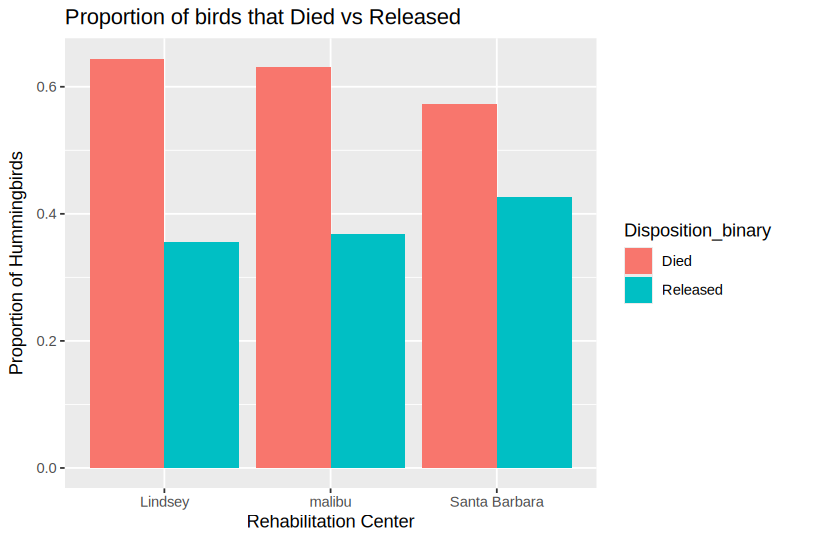

In [ ]:
proportions <- model_data %>%
  group_by(Place, Disposition_binary) %>%
  summarise(count = n_distinct(ID), .groups = "drop") %>%
  group_by(Place) %>%
  mutate(proportion = count / sum(count))
proportions

ggplot(proportions, aes(x = Place, y = proportion, fill = Disposition_binary)) +
  geom_col(position = "dodge") +
  xlab("Rehabilitation Center") +
  ylab("Proportion of Hummingbirds") +
  labs(title = "Proportion of birds that Died vs Released")

## 🧬 Case file 4 · Green birds vs. orange birds

**Q13 (5 pts).** Make a new column `Species_group` with two groups:
* **`Selasphorus`**: all *Selasphorus* birds
* **`Non-selasphorus`**: Anna's (ANHU), Black-chinned (BCHU) and unidentified non-*Selasphorus* birds

Then tabulate and plot survival by `Species_group`. **Do survival proportions differ between the groups?**

✅ *Check yourself:* the dataset already has a `Green_Orange` column. If your grouping is right, `table(model_data$Species_group, model_data$Green_Orange)` has zeros off the diagonal.

<details><summary>💡 <b>Hint</b> (try first!)</summary>

There is only **one** value that belongs in the `Selasphorus` group, so a single `ifelse()` does it: *if* `Species_e` is `"Selasphorus"`, then `"Selasphorus"`, *else* `"Non-selasphorus"`.

</details>

                 
                  Non-selasphorus spp. Selasphorus spp.
  non-Selasphorus                 4122                0
  Selasphorus                        0              878

Species_group,Disposition_binary,count,proportion2
<chr>,<chr>,<int>,<dbl>
Selasphorus,Died,558,0.6355353
Selasphorus,Released,320,0.3644647
non-Selasphorus,Died,2648,0.6424066
non-Selasphorus,Released,1474,0.3575934


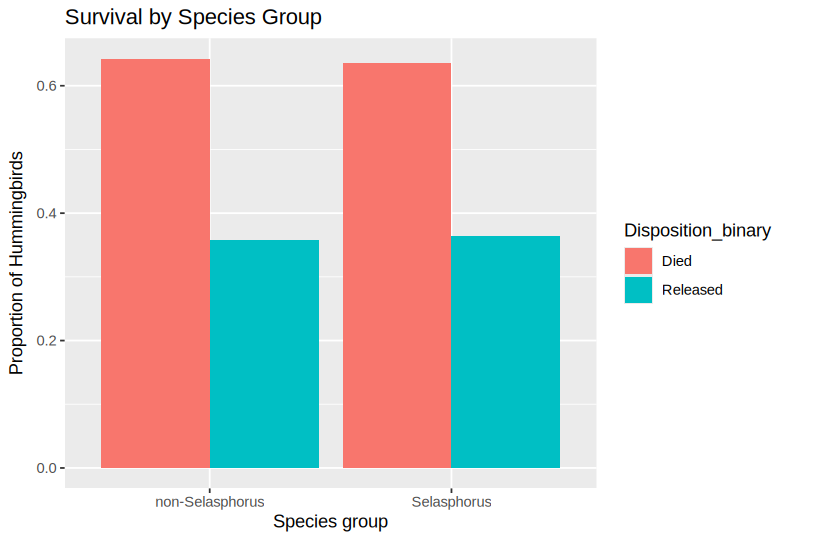

In [ ]:
model_data$Species_group <- ifelse(model_data$Species_e == "Selasphorus", "Selasphorus", "non-Selasphorus" )

table(model_data$Species_group, model_data$Green_Orange)   # self-check

species_distribution <- model_data %>%
  group_by(Species_group, Disposition_binary) %>%
  summarise(count = n_distinct(ID), .groups = "drop")%>%
  group_by(Species_group) %>%
  mutate(proportion2 = count / sum(count))
species_distribution

ggplot(species_distribution, aes(x = Species_group, y = proportion2, fill = Disposition_binary)) +
  geom_col(position = "dodge") +
  xlab("Species group") +
  ylab("Proportion of Hummingbirds") +
  labs(title = "Survival by Species Group")



✍️ **Your answer:**

Survival proportions does not seems to differ between species groups, the proportion for both of them is around ~35%.

## ⏳ Case file 5 · Time traveller: admissions over the years

**Q14 (2 pts).** Convert `Admitted` to a real date. Then explain what the `format` argument does, and what would happen if you used `"%d/%m/%Y"` instead.

In [ ]:
model_data$Admitted <- as.Date(model_data$Admitted, format = "%d/%m/%Y")
head(model_data)
head(model_data$Admitted)
class(model_data$Admitted)
range(model_data$Admitted)

,Admitted,Disposition_binary,Place,F_Aid,Species_e,Sex_e,Age_e,Brought_in_after,season,r,Green_Orange,ID,Species_group
,<date>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>
1,1991-09-07,Released,Lindsey,No,Non-selasphorus,unknown,Nestling,0,Summer,found on the ground,Non-selasphorus spp.,145_ANHU,non-Selasphorus
2,NA,Died,Lindsey,No,ANHU,Female-like,adult-like,0,Winter,found inside,Non-selasphorus spp.,5160_ANHU,non-Selasphorus
3,NA,Died,Lindsey,Yes,ANHU,Female-like,adult-like,2,Spring,found on the ground,Non-selasphorus spp.,626_ANHU,non-Selasphorus
4,NA,Released,Lindsey,No,Non-selasphorus,unknown,Nestling,0,Summer,unknown,Non-selasphorus spp.,1277_ANHU,non-Selasphorus
5,NA,Died,Lindsey,No,Selasphorus,Female-like,adult-like,0,Summer,unknown,Selasphorus spp.,348_RUHU,Selasphorus
6,NA,Died,malibu,No,Selasphorus,Female-like,adult-like,0,Spring,unknown,Selasphorus spp.,6431_ALHU,Selasphorus


[1] "1991-09-07" NA           NA           NA           NA          
[6] NA

[1] "Date"

[1] NA NA

✍️ **Your answer:**

With this code, we are modifying our model_data data frame, specifically the Admitted column, from a character data type to a Date data type. In the code, we are telling R how our dates are formatted so it can interpret them in the correct order: month, day, and year. However, when we change the format to "%d/%m/%Y", we are giving R a different order (day, month, and year), which could result in incorrectly interpreted dates.

**Q15 (4 pts).** 🔮 *Predict first:* which **season** do you think brings the most hummingbirds into care? `Winter` Why?
1. I would predict Winter because hummingbirds might be more vulnerable during this season due to colder temperatures and reduced food availability.

Now count admissions per **month** and per **year**, and plot both timelines. Was your season prediction right? (`table(model_data$season)` will tell you.)

In [ ]:
admissions_by_month <- model_data %>%
  mutate(Admitted_month = format(Admitted, "%Y-%m")) %>%
  filter(!is.na(Admitted), !is.na(ID)) %>%
  group_by(Admitted_month) %>%
  summarise (count3 = n_distinct(ID), .groups = "drop") %>%
  mutate(proportion3 = count3 / sum(count3))

admissions_by_year <- model_data %>%
  mutate(Admitted_year = format(Admitted, "%Y")) %>%
  filter(!is.na(Admitted), !is.na(ID)) %>%
  group_by(Admitted_year) %>%
  summarise(count4 = n_distinct(ID), .groups = "drop") %>%
  mutate(proportion4 = count4 / sum(count4))

(table(model_data$season))


  Fall Spring Summer Winter 
   423   2248   1594    735 

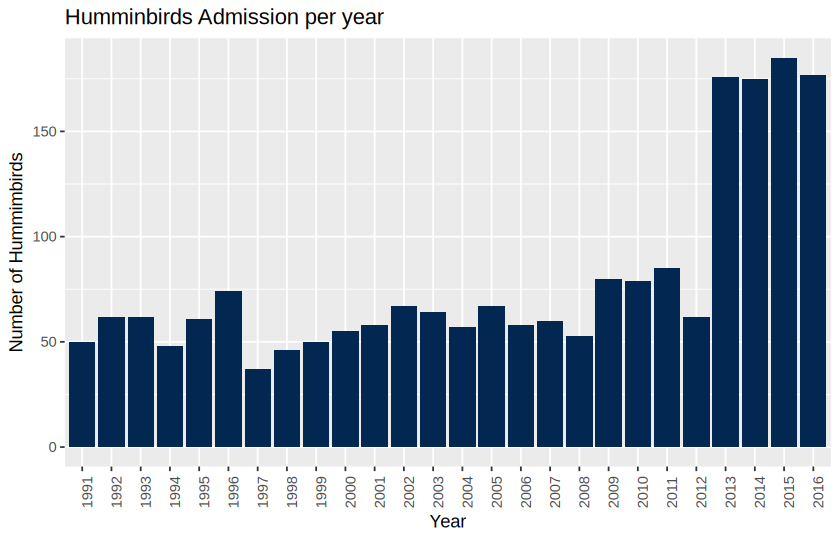

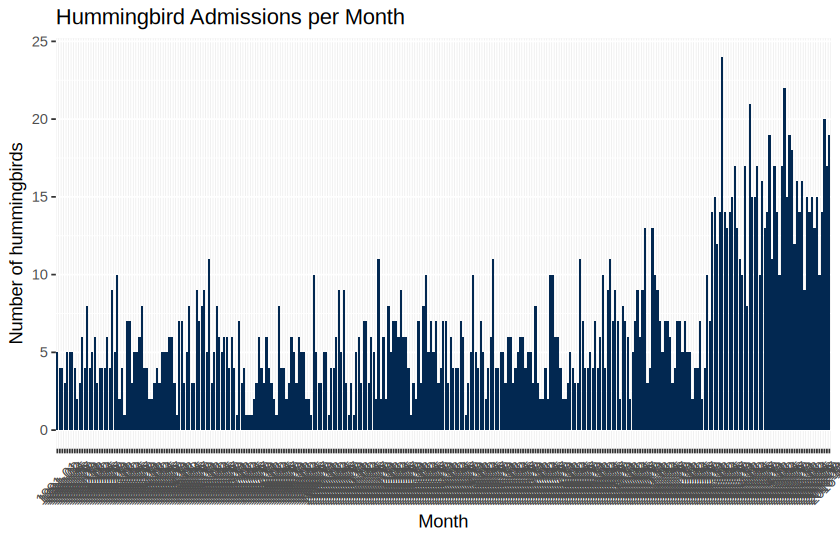

In [ ]:
ggplot(admissions_by_year, aes(x = Admitted_year, y = count4)) +
  geom_col(fill = "#022851") +
  xlab("Year") +
  ylab("Number of Hummimbirds") +
  labs(title = "Humminbirds Admission per year") +
  theme(axis.text.x = element_text(angle = 90, vjust = 1))

ggplot(admissions_by_month, aes(x = Admitted_month, y = count3)) +
  geom_col(fill = "#022851") +
  xlab("Month") +
  ylab("Number of hummingbirds") +
  labs(title = "Hummingbird Admissions per Month") +
  theme(axis.text.x = element_text(angle = 45, vjust = 0.5))



## now plot admissions_by_month the same way

**Q16 (2 pts).** 🕵️ **Plot twist.** Admissions roughly **triple** from 2013 onwards. Did hummingbirds suddenly get into three times more trouble? Find out what really changed.

<details><summary>💡 <b>Hint</b> (try first!)</summary>

Count admissions by year **and** `Place`: `model_data %>% count(Admitted_year = format(Admitted_date, "%Y"), Place)`. When does each center first appear?

</details>

In [ ]:
admissions_by_place <- model_data %>%
  count(Admitted_year = format(Admitted, "%Y"),Place)

admissions_by_place
# your investigation here

Admitted_year,Place,n
<chr>,<chr>,<int>
1991,Lindsey,50
1992,Lindsey,62
1993,Lindsey,62
1994,Lindsey,48
1995,Lindsey,61
1996,Lindsey,74
1997,Lindsey,37
1998,Lindsey,46
1999,Lindsey,50


✍️ **Your answer:**

Before 2013, the database included data from only one rehabilitation center, Lindsey. Starting in 2013, two additional rehab centers joined the database, which explains the increase in the number of admissions recorded after that year.

## 🕵️ Bonus · Data detective (+5 pts)

Real data are messy, and these data have **at least three problems** hiding in the *raw* file (`data`). Find three, show the code that reveals each one, and say how you would fix it **without overwriting the raw file**.

<details><summary>💡 <b>Hint</b> (try first!)</summary>

Try `summary(data$Brought_in_after)`, `unique(data$Sex_e)` (look *very* closely at the spaces), and `unique(data$Place)` (look at capitalisation).

</details>

In [ ]:
head(data)
summary(data$Brought_in_after)
unique (data$Brought_in_after)
unique(data$Sex_e)
unique(data$Place)
# your detective work here

,Admitted,Disposition_binary,Place,F_Aid,Species_e,Sex_e,Age_e,Brought_in_after,season,r,Green_Orange,ID
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<chr>,<chr>
1,1/2/1991,Died,Lindsey,No,ANHU,Female-like,adult-like,1,Winter,found on the ground,Non-selasphorus spp.,1_ANHU
2,1/2/1991,Released,Lindsey,Yes,ANHU,Female-like,adult-like,0,Winter,unknown,Non-selasphorus spp.,2_ANHU
3,1/4/1991,Died,Lindsey,No,ANHU,Female-like,adult-like,0,Winter,suspect torpor-like state,Non-selasphorus spp.,3_ANHU
4,1/5/1991,Died,Lindsey,No,ANHU,Female-like,adult-like,4,Winter,unknown,Non-selasphorus spp.,4_ANHU
5,1/5/1991,Died,Lindsey,No,ANHU,Female-like,adult-like,0,Winter,caught by domestic animal,Non-selasphorus spp.,5_ANHU
6,1/5/1991,Died,Lindsey,No,ANHU,Female-like,adult-like,0,Winter,found on the ground,Non-selasphorus spp.,6_ANHU


     Min.   1st Qu.    Median      Mean   3rd Qu.      Max. 
 -365.000     0.000     0.000     3.058     1.000 16588.000 

[1]     1     0     4     2     6     3    15     5    10    31     8    22
[13]     9    13     7    30    14    32    27    11    21    18    24    17
[25]    28    19    23    20    16    -1   367  -365    -3   -26   122 16588
[37]  -182   180   289   290   262   244   241   -79  -159   -31  -207  -247
[49]   -27   -25   -44   -48   -49   -62   -37   -68   -70   -81    -2   -47

[1] "Female-like " "unknown"      "Male"

[1] "Lindsey"       "malibu"        "Santa Barbara"

✍️ **Your answer:**

## 💭 Debrief (2 pts)

**Q17.** In two or three sentences: (a) one thing in this data that surprised you, and (b) one R error you hit and how you fixed it.

✍️ **Your answer:**

One thing that surprised me was that I though there were gonna be more nesting-birds that die compare to adults.
And one error was that admitted_date is actually saved as admitted, so it took me a while to figure this out.

## 🎨 Hall of Fame (optional, not graded)
Make your **most beautiful** plot from this dataset, in Aggie Blue `#022851` and Aggie Gold `#FFBF00`. The best ones get shown in class. 🏆

## 📤 How to submit
1. Run every cell from the top (**Runtime → Restart and run all**) so the outputs are fresh.
2. Save the notebook to **your branch** of the course GitHub repo: File → Save a copy in GitHub (**never `main`**).
3. Download and submit `Hummingbird_data_YOURNAME.csv` and `rehab_counts_YOURNAME.pdf` from `outputs/`.

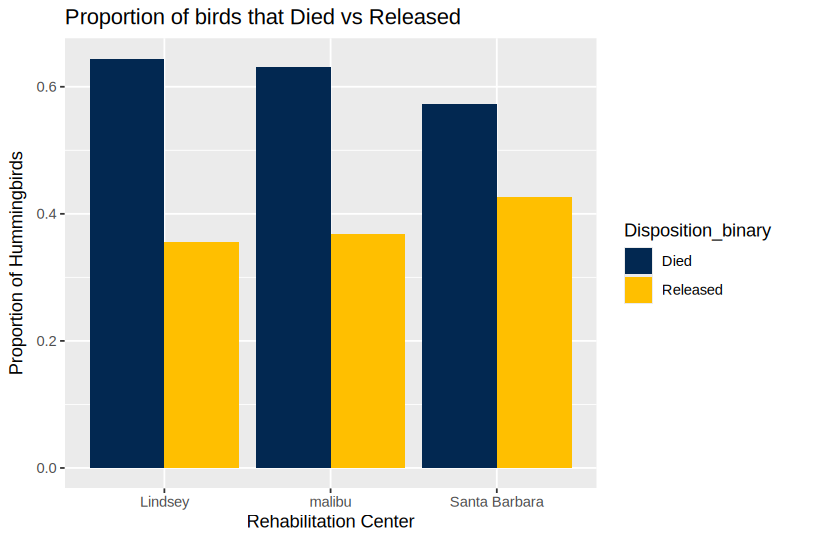

In [ ]:
ggplot(proportions, aes(x = Place, y = proportion, fill = Disposition_binary)) +
  geom_col(position = "dodge") +
  scale_fill_manual(
    values = c( "Died" = "#022851",
      "Released" = "#FFBF00")) +
  xlab("Rehabilitation Center") +
  ylab("Proportion of Hummingbirds") +
  labs(title = "Proportion of birds that Died vs Released")

In [ ]:
beep_colab("smb_stage_clear")   # mission complete 🍄